# 01 · Exploratory data analysis: CTSSB-1M

Reads the dataset produced by `codeguard prepare-data -c configs/prototype/data_5k.yaml` and the cached filtered pool (all 714k in-function pairs). All data logic lives in `src/codeguard/data/`; this notebook only measures and plots.

Figures go to `results/figures/eda/`, key numbers to `results/eda_summary.json`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from codeguard.data.pipeline import load_pairs
from codeguard.data.quality import parses_as_python3
from codeguard.data.split import SPLITS

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data/processed/ctssb_5k"
FIG = ROOT / "results/figures/eda"
FIG.mkdir(parents=True, exist_ok=True)

manifest = json.loads((DATA / "manifest.json").read_text(encoding="utf-8"))
pairs = pd.concat([load_pairs(DATA, s) for s in SPLITS], ignore_index=True)
pool = pd.read_parquet(
    ROOT / manifest["pool_cache"],
    columns=["project", "sstub_pattern", "is_py2", "py2_markers", "n_lines"],
)
summary = {}  # key numbers for the report
print(f"pool (in-function pairs): {len(pool):,}   sample: {len(pairs):,}")

pool (in-function pairs): 714,241   sample: 5,000


In [2]:
# Chart style: one axis per chart, recessive grid, text in ink colours, not series colours.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False,
})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

## 1. Filtering funnel

In CTSSB-1M every record already has `likely_bug=True` and `comodified=False`, so `in_function` is the only record filter that removes rows. Deduplication (whitespace-insensitive, on the `(buggy, fixed)` pair) removes identical changes, mostly the same commit mirrored in forks.

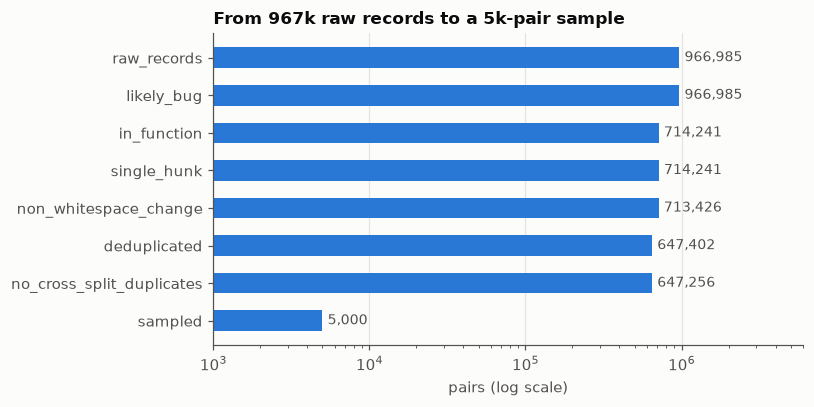

In [3]:
funnel = pd.Series(manifest["funnel"])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
y = np.arange(len(funnel))[::-1]
ax.barh(y, funnel.to_numpy(), color=BLUE, height=0.55)
for yi, v in zip(y, funnel.to_numpy()):
    ax.text(v * 1.08, yi, f"{v:,}", va="center", color=INK2, fontsize=9)
ax.set_yticks(y, funnel.index)
ax.set_xscale("log")
ax.set_xlim(1e3, 6e6)
ax.set_xlabel("pairs (log scale)")
ax.grid(axis="y", visible=False)
ax.set_title("From 967k raw records to a 5k-pair sample")
save(fig, "01_funnel")
summary["funnel"] = manifest["funnel"]

## 2. Splits

Split 80/10/10 by **project** with `GroupShuffleSplit` (seed 42) over the whole deduplicated pool, then sampled. Fractions are over projects, so row fractions in the pool drift slightly; the sample is exactly 4000/500/500.

In [4]:
rows = []
for level in ("pool", "sample"):
    for split, st in manifest[level]["splits"].items():
        rows.append({"level": level, "split": split, **st})
split_table = pd.DataFrame(rows).set_index(["level", "split"])
summary["splits"] = {f"{a}/{b}": r for (a, b), r in split_table.to_dict("index").items()}
split_table

pairs  groups  row_fraction  python2_share
level  split                                             
pool   train  512633  106413        0.7920         0.0545
       val     68407   13294        0.1057         0.0537
       test    66216   13297        0.1023         0.0576
sample train    4000    3392        0.8000         0.0590
       val       500     417        0.1000         0.0540
       test      500     424        0.1000         0.0600

In [5]:
leak = manifest["leakage"]
print("cross-split snippet duplicates before drop:", leak["cross_split_duplicates_before_drop"])
print("dropped (val/test):", leak["dropped_cross_split_duplicates"])
print("pool  :", {k: v for k, v in leak["pool"].items()})
print("sample:", {k: v for k, v in leak["sample"].items()})
print("project names with >1 repository URL (forks):",
      manifest["pool"]["groups_with_multiple_urls (forks)"])
summary["leakage"] = leak

cross-split snippet duplicates before drop: {'train-val': 66, 'train-test': 78, 'val-test': 5}
dropped (val/test): {'val': 66, 'test': 80}
pool  : {'shared_groups': {'train-val': 0, 'train-test': 0, 'val-test': 0}, 'pairs_in_multiple_splits': 0, 'cross_split_snippet_duplicates': {'train-val': 0, 'train-test': 0, 'val-test': 0}, 'label_conflict_snippets': 19683}
sample: {'shared_groups': {'train-val': 0, 'train-test': 0, 'val-test': 0}, 'pairs_in_multiple_splits': 0, 'cross_split_snippet_duplicates': {'train-val': 0, 'train-test': 0, 'val-test': 0}, 'label_conflict_snippets': 2}
project names with >1 repository URL (forks): 12533


**Label conflicts** are snippets that are the *fixed* side of one pair and the *buggy* side of another, e.g. a statement fixed twice in a row (A→B, then B→C) or a revert. They are not leakage, but irreducible label noise for snippet-level classification, and a reminder that "fixed" means "changed by a later commit", not "correct".

## 3. Length in DeepSeek-Coder tokens

Measured with the tokenizer of the model we fine-tune (`deepseek-ai/deepseek-coder-1.3b-instruct`), because this decides `max_seq_len`.

In [6]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("deepseek-ai/deepseek-coder-1.3b-instruct")


def n_tokens(texts):
    ids = tok(list(texts), add_special_tokens=False)["input_ids"]
    return np.array([len(x) for x in ids])


pairs["buggy_tokens"] = n_tokens(pairs["buggy"])
pairs["fixed_tokens"] = n_tokens(pairs["fixed"])
pairs["fixed_line_tokens"] = n_tokens(pairs["added_lines"])
# rough upper bound for a generation training example: prompt (~80 tokens) + buggy + fixed
pairs["gen_example_tokens"] = pairs["buggy_tokens"] + pairs["fixed_tokens"] + 80

cols = ["n_lines", "buggy_tokens", "fixed_line_tokens", "gen_example_tokens"]
pct = pairs[cols].quantile([0.5, 0.9, 0.95, 0.99]).T
pct["max"] = pairs[cols].max()
pct.columns = ["p50", "p90", "p95", "p99", "max"]
summary["length_percentiles"] = pct.round(1).to_dict("index")
pct.round(1)

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


,p50,p90,p95,p99,max
n_lines,7.0,7.0,7.0,7.0,30
buggy_tokens,82.0,129.1,149.1,200.0,5082
fixed_line_tokens,19.0,37.0,46.0,71.0,1345
gen_example_tokens,246.0,340.0,380.1,483.0,10251


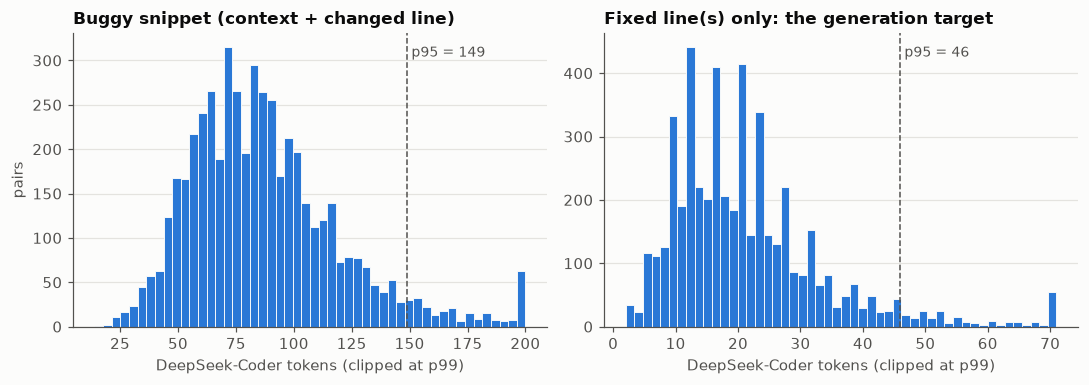

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col, title in [
    (axes[0], "buggy_tokens", "Buggy snippet (context + changed line)"),
    (axes[1], "fixed_line_tokens", "Fixed line(s) only: the generation target"),
]:
    values = pairs[col]
    cap = values.quantile(0.99)
    ax.hist(values.clip(upper=cap), bins=50, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
    p95 = values.quantile(0.95)
    ax.axvline(p95, color=INK2, linestyle="--", linewidth=1)
    ax.text(p95, ax.get_ylim()[1] * 0.92, f" p95 = {p95:.0f}", color=INK2, fontsize=9)
    ax.set_title(title)
    ax.set_xlabel("DeepSeek-Coder tokens (clipped at p99)")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("pairs")
save(fig, "02_token_lengths")

## 4. Bug patterns (`sstub_pattern`)

The sample should mirror the pool. `SINGLE_STMT` is the catch-all for changes that match none of the 22 named SStuB patterns.

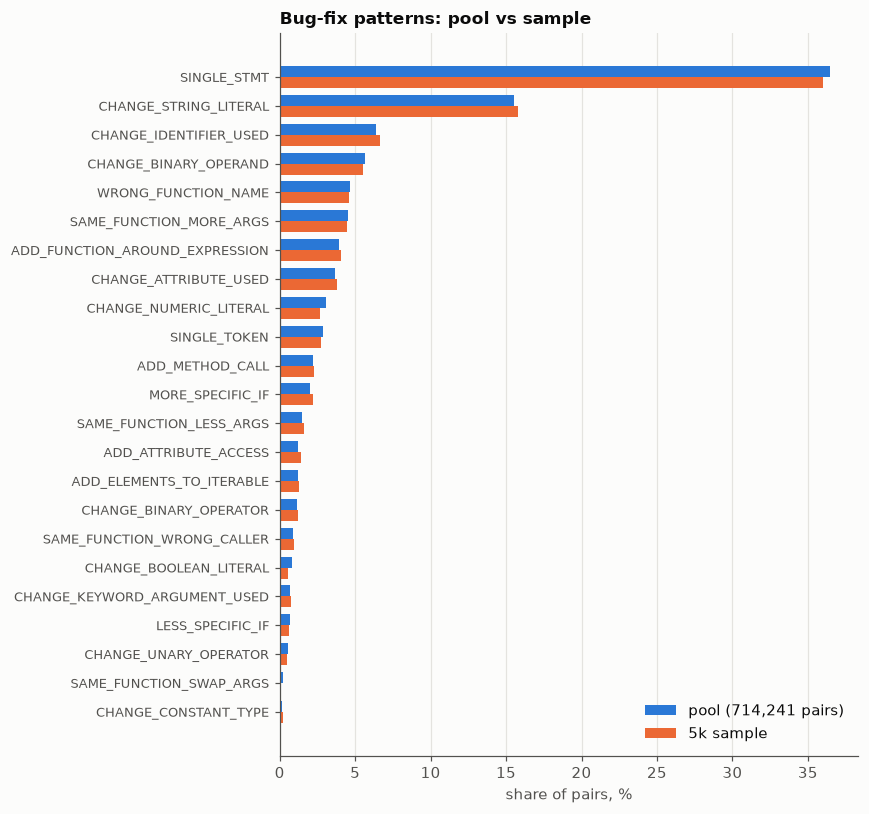

largest pool-vs-sample difference: 0.50 percentage points


In [8]:
pool_share = pool["sstub_pattern"].value_counts(normalize=True)
sample_share = pairs["sstub_pattern"].value_counts(normalize=True).reindex(pool_share.index).fillna(0)
order = pool_share.index[::-1]
y = np.arange(len(order))
h = 0.38
fig, ax = plt.subplots(figsize=(8, 7.5))
ax.barh(y + h / 2, pool_share[order] * 100, height=h, color=BLUE, label=f"pool ({len(pool):,} pairs)")
ax.barh(y - h / 2, sample_share[order] * 100, height=h, color=ORANGE, label=f"5k sample")
ax.set_yticks(y, order, fontsize=8.5)
ax.set_xlabel("share of pairs, %")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Bug-fix patterns: pool vs sample")
save(fig, "03_sstub_patterns")
summary["sstub_share_sample"] = sample_share.round(4).to_dict()
max_diff = (sample_share - pool_share).abs().max() * 100
print(f"largest pool-vs-sample difference: {max_diff:.2f} percentage points")

## 5. Python 2 code

Detected with syntax markers that are valid only in Python 2 (`codeguard.data.quality.PY2_MARKERS`): a lower bound (a Python 2 snippet without any marker is not counted) with rare false positives (markers inside strings). We **keep** Python 2 pairs (`drop_python2: false`) and report results separately.

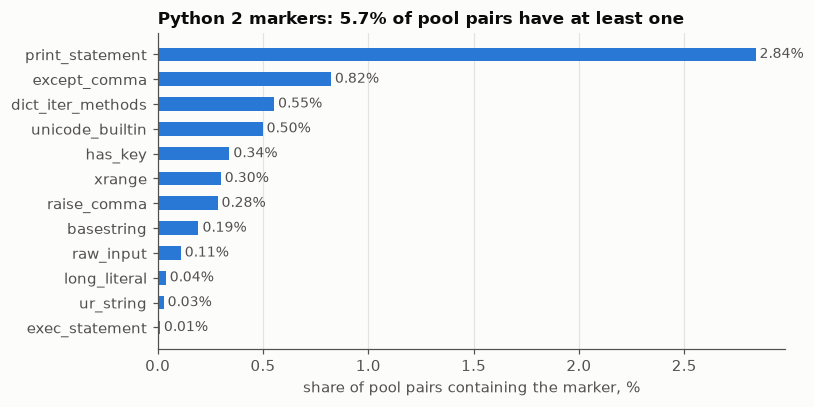

,buggy_parses,fixed_parses
is_py2,,
False,0.413,0.415
True,0.150,0.160


In [9]:
markers = pool["py2_markers"].str.split(",").explode()
markers = markers[markers != ""].value_counts() / len(pool) * 100
fig, ax = plt.subplots(figsize=(7.5, 3.8))
y = np.arange(len(markers))[::-1]
ax.barh(y, markers.to_numpy(), color=BLUE, height=0.55)
for yi, v in zip(y, markers.to_numpy()):
    ax.text(v, yi, f" {v:.2f}%", va="center", color=INK2, fontsize=9)
ax.set_yticks(y, markers.index)
ax.set_xlabel("share of pool pairs containing the marker, %")
ax.grid(axis="y", visible=False)
py2_pool = pool["is_py2"].mean() * 100
ax.set_title(f"Python 2 markers: {py2_pool:.1f}% of pool pairs have at least one")
save(fig, "04_python2_markers")

pairs["buggy_parses"] = pairs["buggy"].map(parses_as_python3)
pairs["fixed_parses"] = pairs["fixed"].map(parses_as_python3)
parse = pairs.groupby("is_py2")[["buggy_parses", "fixed_parses"]].mean().round(3)
summary["python2"] = {"pool_share": round(py2_pool / 100, 4),
                      "sample_share": round(float(pairs["is_py2"].mean()), 4),
                      "py3_parse_rate_by_is_py2": parse.to_dict("index")}
parse

`ast.parse` rate is a weak signal: snippets are fragments of a function (an `else:` without its `if`, an unclosed call), so many valid Python 3 snippets fail too. The gap between the two rows is what matters.

## 6. Project concentration

A few large repositories contribute many pairs. This is why the split is grouped by project: otherwise a model could memorise project-specific identifiers.

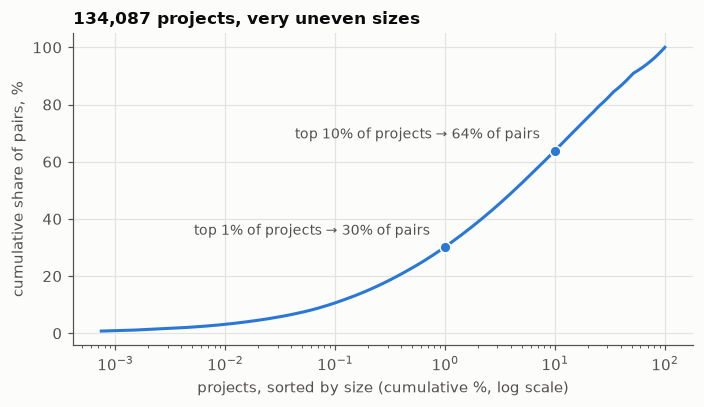

{'n_projects_pool': 134087,
 'largest_project_pairs': 5523,
 'median_pairs_per_project': 2.0,
 'max_pairs_per_project_in_sample': 11}

In [10]:
per_project = pool["project"].value_counts().to_numpy()
cum_share = np.cumsum(per_project) / per_project.sum() * 100
x = np.arange(1, len(per_project) + 1) / len(per_project) * 100
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(x, cum_share, color=BLUE, linewidth=2)
for top in (1, 10):
    k = int(len(per_project) * top / 100)
    ax.plot(x[k - 1], cum_share[k - 1], "o", color=BLUE, markersize=7, markeredgecolor=SURFACE)
    ax.annotate(f"top {top}% of projects → {cum_share[k - 1]:.0f}% of pairs",
                (x[k - 1], cum_share[k - 1]), xytext=(-10, 8), textcoords="offset points", ha="right",
                color=INK2, fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("projects, sorted by size (cumulative %, log scale)")
ax.set_ylabel("cumulative share of pairs, %")
ax.set_title(f"{len(per_project):,} projects, very uneven sizes")
save(fig, "05_project_concentration")
summary["projects"] = {"n_projects_pool": int(len(per_project)),
                       "largest_project_pairs": int(per_project[0]),
                       "median_pairs_per_project": float(np.median(per_project)),
                       "max_pairs_per_project_in_sample": int(pairs["project"].value_counts().iloc[0])}
summary["projects"]

## 7. Examples

In [11]:
for _, row in pairs.sample(3, random_state=42).iterrows():
    print(f"[{row.split}] {row.project}  {row.sstub_pattern}  py2={row.is_py2}")
    print("--- removed:", row.removed_lines.strip())
    print("+++ added:  ", row.added_lines.strip())
    print(row.buggy)
    print("=" * 80)

[train] net_tc_tcconfig  SINGLE_STMT  py2=False
--- removed: def verify_network_interface(self, device):
+++ added:   def verify_network_interface(device):
VERSION = "0.4.0"


def verify_network_interface(self, device):
    import netifaces

    if device not in netifaces.interfaces():
[train] transmission  CHANGE_STRING_LITERAL  py2=False
--- removed: "detail": "Error 404, page not foud",
+++ added:   "detail": "Error 404, page not found",
    data = {
        "errors": [{
            "detail": "Error 404, page not foud",
            "status": "404"
        }]
    }
[train] Nurevam  SINGLE_STMT  py2=False
--- removed: enable_level.append([server_list[server_id],server_icon[server_id],server_id,
+++ added:   enable_level.append([server_list[server_id],server_icon.get(server_id),server_id,
                total = sum(player_total)
                level = int(math.log(total/100,3))
                next_xp = int(100*3**(level+1))
                enable_level.append([server_list[server_id]

In [12]:
(ROOT / "results/eda_summary.json").write_text(
    json.dumps(summary, indent=2, default=float) + "\n", encoding="utf-8"
)
print("saved results/eda_summary.json")

saved results/eda_summary.json
